# Wheat price forecasting from weather and WASDE data

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import re
import time
from io import StringIO
from lxml import html
from pathlib import Path
from urllib.parse import urljoin
from bs4 import BeautifulSoup
from tqdm import tqdm
from io import BytesIO
from pypdf import PdfReader
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 1. Wheat Price Series

The notebook starts with the IMF monthly wheat price series in U.S. dollars. The API response is stored first so it can be parsed and checked separately from downstream modeling.


In [32]:
IMF_WHEAT_URL = (
    "https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/"
    "*.PWHEAMT.USD.M?c%5BTIME_PERIOD%5D=ge:1956-12-31le:2026-09-30"
    "&attributes=all&detail=full&includeHistory=true&limit=100"
)

response = requests.get(
    IMF_WHEAT_URL,
    headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"},
    timeout=60,
)
response.raise_for_status()
imf_payload = response.json()
print(f"HTTP status: {response.status_code}")

HTTP status: 200


The SDMX response is converted into a tidy monthly DataFrame with one date and one wheat price. Dates are sorted and duplicate or entirely missing observations are rejected. We inspect the series and notice that it starts in 1992 and goes up to 2026.


In [33]:
def parse_imf_sdmx_series(payload):
    data = payload["data"]
    structure = data["structures"][0]
    time_values = structure["dimensions"]["observation"][0]["values"]
    observations = data["dataSets"][0]["series"]
    
    if len(observations) != 1:
        raise ValueError(f"Expected one wheat series, found {len(observations)}")
    
    series = next(iter(observations.values()))["observations"]
    rows = []
    for index, observation in series.items():
        period_label = time_values[int(index)]["value"].replace("-M", "-")
        rows.append(
            {
                "date": pd.to_datetime(period_label, format="%Y-%m"),
                "wheat_price_usd": pd.to_numeric(observation[0], errors="coerce"),
            }
        )
        
    result = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    
    if result["date"].duplicated().any():
        raise ValueError("IMF response produced duplicate monthly dates")
    if result["wheat_price_usd"].isna().all():
        raise ValueError("IMF wheat series contains no numeric observations")
    
    return result

wheat = parse_imf_sdmx_series(imf_payload)
print("First 5 rows of the wheat data:")
print(wheat.head())
print("Last 5 rows of the wheat data:")
print(wheat.tail())

First 5 rows of the wheat data:
        date  wheat_price_usd
0 1992-01-01       169.954773
1 1992-02-01       177.130600
2 1992-03-01       169.350739
3 1992-04-01       159.931198
4 1992-05-01       149.689117
Last 5 rows of the wheat data:
          date  wheat_price_usd
412 2026-05-01       220.884552
413 2026-06-01       199.648288
414 2026-07-01       228.738845
415 2026-08-01       237.855402
416 2026-09-01       246.851802


The target is the next month's log return. This makes the prediction task explicit and provides the forward return used later for out-of-sample evaluation.


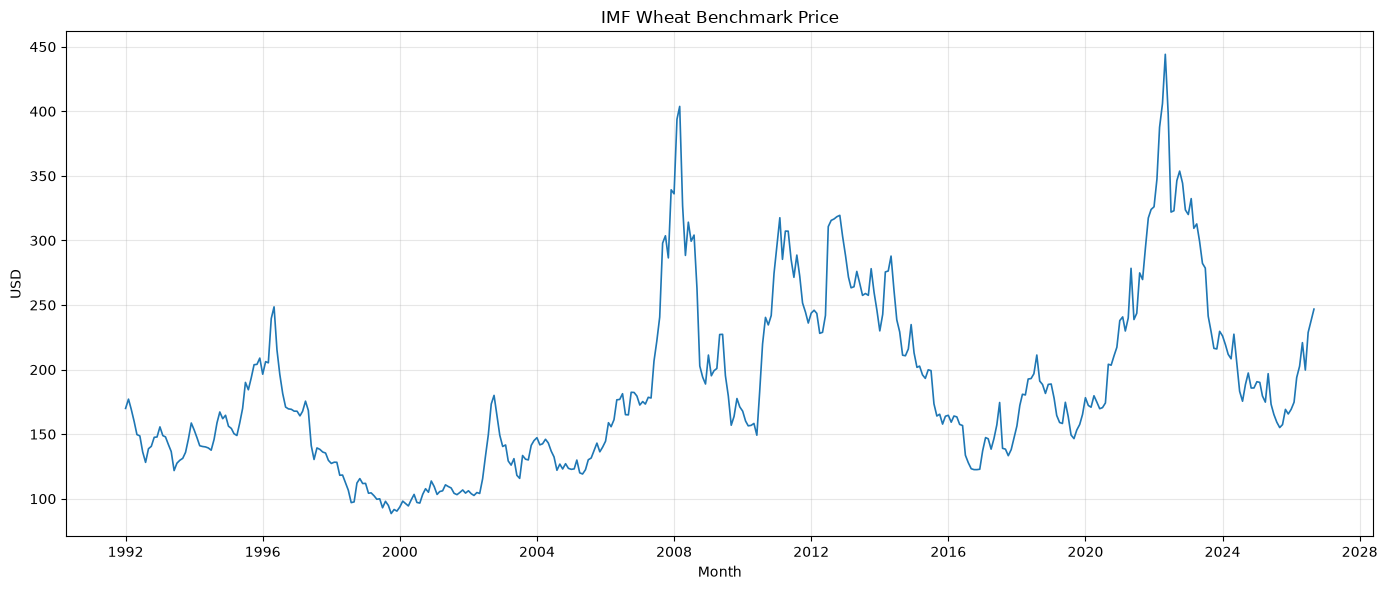

In [34]:
wheat["target_return_1m"] = (
    np.log(wheat["wheat_price_usd"].shift(-1))
    - np.log(wheat["wheat_price_usd"])
)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(wheat["date"], wheat["wheat_price_usd"], linewidth=1.2)
ax.set_title("IMF Wheat Benchmark Price")
ax.set_xlabel("Month")
ax.set_ylabel("USD")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 2. Weather and WASDE inputs

NOAA RONI data are downloaded and reshaped from seasonal observations into a monthly time series. Each three-month value is assigned to its ending month.


In [35]:
roni_page_url = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/"

roni_response = requests.get(roni_page_url, timeout=60)
roni_response.raise_for_status()

document = html.fromstring(roni_response.content)
matches = document.xpath(
    "/html/body/table[4]/tbody/tr/td[2]/table/tbody/tr[2]/td/div[1]/table[2]"
)

if len(matches) != 1:
    raise ValueError(f"Expected one target table, found {len(matches)}")

roni_table = pd.read_html(
    StringIO(html.tostring(matches[0], encoding="unicode"))
)[0]

roni_table

,Year The year,DJF Dec Jan Feb,JFM Jan Feb Mar,FMA Feb Mar Apr,MAM Mar Apr May,AMJ Apr May Jun,MJJ May Jun Jul,JJA Jun Jul Aug,JAS Jul Aug Sep,ASO Aug Sep Oct,SON Sep Oct Nov,OND Oct Nov Dec,NDJ Nov Dec Jan
0,1950,-1.2,-1.1,-1.0,-1.0,-1.0,-0.7,-0.4,-0.3,-0.3,-0.4,-0.4,-0.5
1,1951,-0.3,0.1,0.5,0.6,0.6,0.7,0.8,1.0,1.0,1.0,0.9,0.7
2,1952,0.7,0.3,0.5,0.2,0.0,-0.4,-0.4,-0.1,0.1,0.0,-0.1,0.1
3,1953,0.4,0.7,0.7,0.7,0.9,0.8,0.7,0.7,0.7,0.8,0.6,0.7
4,1954,0.6,0.6,0.3,0.0,-0.2,-0.2,-0.4,-0.6,-0.5,-0.3,-0.1,-0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,2022,-1.2,-1.1,-1.2,-1.3,-1.2,-0.9,-0.9,-0.9,-1.1,-1.1,-1.1,-1.0
80,2023,-0.9,-0.7,-0.5,-0.3,0.0,0.3,0.5,0.8,1.0,1.3,1.4,1.4
81,2024,1.1,0.8,0.4,0.0,-0.3,-0.4,-0.5,-0.6,-0.7,-0.8,-0.9,-1.0
82,2025,-1.1,-0.8,-0.7,-0.5,-0.5,-0.4,-0.4,-0.6,-0.8,-0.9,-1.0,-1.0


The seasonal RONI observations are mapped to monthly dates and retained as a climate feature that can be aligned with prices without changing the original signal. To align the RONI data with the monthly wheat prices, we keep data from 1992 onward, which is the start of the wheat price series.

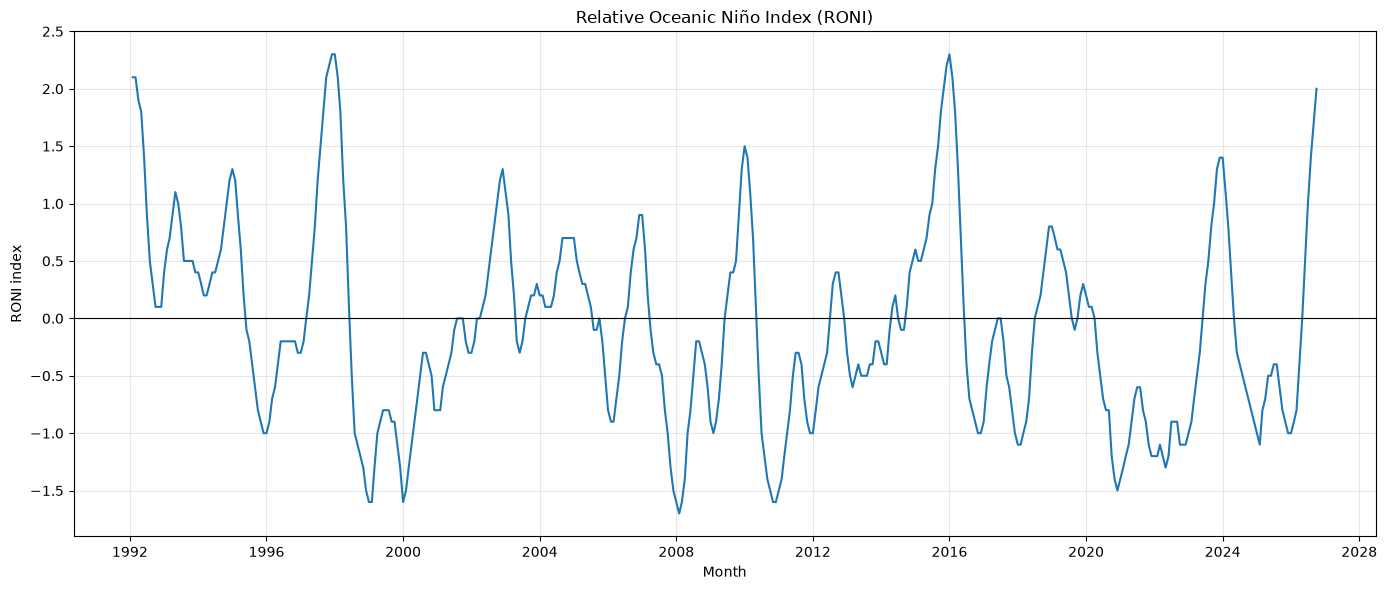

In [36]:
# Assign each three-month RONI value to its ending month
season_end_month = {
    "DJF": 2,
    "JFM": 3,
    "FMA": 4,
    "MAM": 5,
    "AMJ": 6,
    "MJJ": 7,
    "JJA": 8,
    "JAS": 9,
    "ASO": 10,
    "SON": 11,
    "OND": 12,
    "NDJ": 1,
}

years = pd.to_numeric(roni_table.iloc[:, 0], errors="coerce")
roni_table = roni_table.loc[years.between(1992, 2026)].copy()
roni_plot = roni_table.rename(columns={roni_table.columns[0]: "year"}).copy()
roni_plot["year"] = pd.to_numeric(roni_plot["year"], errors="coerce")
roni_long = roni_plot.melt(
    id_vars="year", var_name="season_label", value_name="roni_index"
)
roni_long["season"] = roni_long["season_label"].str.extract(
    r"^(DJF|JFM|FMA|MAM|AMJ|MJJ|JJA|JAS|ASO|SON|OND|NDJ)", expand=False
)

if roni_long["season"].isna().any():
    raise ValueError("RONI table contains an unrecognized season column")

roni_long["month"] = roni_long["season"].map(season_end_month)
roni_long["roni_index"] = pd.to_numeric(
    roni_long["roni_index"], errors="coerce"
)
roni_long["date"] = pd.to_datetime(
    {
        "year": roni_long["year"] + roni_long["month"].eq(1),
        "month": roni_long["month"],
        "day": 1,
    }
)
roni_monthly = roni_long[["date", "roni_index", "season"]].sort_values("date")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(roni_monthly["date"], roni_monthly["roni_index"])
ax.set_title("Relative Oceanic Niño Index (RONI)")
ax.set_xlabel("Month")
ax.set_ylabel("RONI index")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 3. FRED dollar index and WTI inputs
FRED supplies the dollar-index proxy and WTI prices. The historical and current dollar-index series are combined into a continuous monthly index before merging with wheat prices.


In [37]:
FRED_API_URL = "https://api.stlouisfed.org/fred/series/observations"
FRED_API_KEY = "5951323032696d08a9a105cbb886698b"
if not FRED_API_KEY:
    raise RuntimeError(
        "Set the FRED_API_KEY environment variable before running this cell."
    )

FRED_SERIES = {
    "dxy_history": "DTWEXM",
    "dxy_current": "DTWEXBGS",
    "wti_price_usd": "DCOILWTICO",
}

def fetch_fred_series(series_id, column_name):
    response = requests.get(
        FRED_API_URL,
        params={
            "series_id": series_id,
            "api_key": FRED_API_KEY,
            "file_type": "json",
            "observation_start": "1992-01-01",
        },
        timeout=60,
    )
    response.raise_for_status()
    observations = response.json().get("observations")
    if not observations:
        raise ValueError(f"FRED returned no observations for {series_id}")
    result = pd.DataFrame(observations)[["date", "value"]].rename(
        columns={"value": column_name}
    )
    result["date"] = pd.to_datetime(result["date"])
    result[column_name] = pd.to_numeric(result[column_name], errors="coerce")
    return result.dropna(subset=[column_name])

dxy_history_daily = fetch_fred_series(
    FRED_SERIES["dxy_history"], "dxy_history"
)
dxy_current_daily = fetch_fred_series(
    FRED_SERIES["dxy_current"], "dxy_current"
)
wti_daily = fetch_fred_series(FRED_SERIES["wti_price_usd"], "wti_price_usd")

dxy_history_monthly = (
    dxy_history_daily.set_index("date").resample("MS").mean()
)
dxy_current_monthly = (
    dxy_current_daily.set_index("date").resample("MS").mean()
)
overlap = dxy_history_monthly.join(
    dxy_current_monthly, how="inner", lsuffix="_history", rsuffix="_current"
).dropna()

if overlap.empty:
    raise ValueError("FRED dollar-index series have no overlapping observations")

level_ratio = (overlap["dxy_current"] / overlap["dxy_history"]).median()
dxy_history_monthly["dxy_index"] = (
    dxy_history_monthly["dxy_history"] * level_ratio
)
dxy_current_monthly["dxy_index"] = dxy_current_monthly["dxy_current"]
dxy_monthly = pd.concat(
    [dxy_history_monthly[["dxy_index"]], dxy_current_monthly[["dxy_index"]]]
).sort_index()
dxy_monthly = dxy_monthly[~dxy_monthly.index.duplicated(keep="last")]
dxy_monthly = dxy_monthly.reset_index()

fred_monthly = (
    dxy_monthly.merge(wti_daily, on="date", how="outer")
    .set_index("date")
    .resample("MS")
    .mean()
    .reset_index()
)

market_inputs = wheat.merge(fred_monthly, on="date", how="left")
market_inputs.head(30)

,date,wheat_price_usd,target_return_1m,dxy_index,wti_price_usd
0,1992-01-01,169.954773,0.041355,105.568290,18.813158
1,1992-02-01,177.130600,-0.044915,107.745794,19.012500
2,1992-03-01,169.350739,-0.057228,110.505643,18.921818
3,1992-04-01,159.931198,-0.066183,110.065408,20.225263
4,1992-05-01,149.689117,-0.006860,108.711387,20.967368
5,1992-06-01,148.665726,-0.086702,106.319918,22.384545
6,1992-07-01,136.319016,-0.061652,103.837056,21.793182
7,1992-08-01,128.168488,0.079226,102.857995,21.339048
8,1992-09-01,138.735794,0.013214,103.722480,21.886190
9,1992-10-01,140.581284,0.048545,106.325459,21.685909


The macroeconomic series are plotted to verify their time coverage and identify missing or discontinuous observations before modeling.


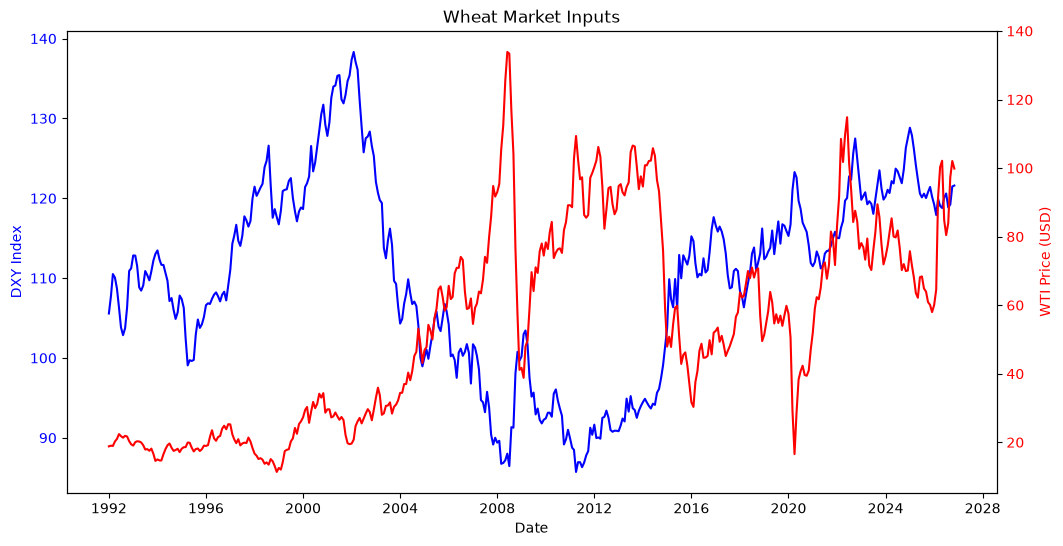

In [38]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(fred_monthly["date"], fred_monthly["dxy_index"], label="DXY Index", color="blue")
ax1.set_xlabel("Date")
ax1.set_ylabel("DXY Index", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(fred_monthly["date"], fred_monthly["wti_price_usd"], label="WTI Price (USD)", color="red")
ax2.set_ylabel("WTI Price (USD)", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Wheat Market Inputs")
plt.show()

### 4. WASDE sentiment features

The reports are converted into monthly wheat narratives and scored in two ways:

- a transparent rule-based financial vocabulary;
- FinBERT, a pretrained transformer classifier.

Both signals are aligned by publication month before being tested against the following month's wheat return.


The crawler follows USDA listing pages, resolves report links, handles changing filenames, and infers dates from reports named `latest` before saving wheat-specific text.


In [39]:
BASE_URL = "https://esmis.nal.usda.gov"
LISTING_URL = f"{BASE_URL}/publication/world-agricultural-supply-and-demand-estimates"
OUTPUT_DIR = Path("./data/wasde_txt_reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36 (Research Project; contact@ensae.fr)"
    )
}

SESSION = requests.Session()
SESSION.headers.update(HEADERS)


def get_report_links_from_page(soup):
    reports = []
    for row in soup.select(".views-row, tr, article"):
        text = row.get_text(" ", strip=True)
        year_match = re.search(r"\b(199[2-9]|20[0-2][0-9])\b", text)
        if not year_match:
            continue
        year = int(year_match.group(0))
        pdf_anchor = row.find("a", href=re.compile(r"\.pdf(?:\?.*)?$", re.I))
        if pdf_anchor:
            reports.append({"year": year, "pdf_url": urljoin(BASE_URL, pdf_anchor["href"])})
            continue
        detail_anchor = row.find("a", href=re.compile(r"/publication/|/reports/", re.I))
        if detail_anchor:
            reports.append({"year": year, "detail_url": urljoin(BASE_URL, detail_anchor["href"])})
    return reports


def extract_pdf_url_from_detail_page(detail_url):
    response = SESSION.get(detail_url, timeout=20)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    link = soup.find("a", href=re.compile(r"\.pdf(?:\?.*)?$", re.I))
    return urljoin(BASE_URL, link["href"]) if link else None


def infer_report_date_from_text(text):
    """Extract the approval date printed in a WASDE PDF header."""
    month_names = (
        "January|February|March|April|May|June|July|August|September|"
        "October|November|December"
    )
    match = re.search(
        rf"(?:Approved by the World Agricultural Outlook Board\s+)?"
        rf"(?P<month>{month_names})\s+(?P<day>[0-3]?\d),?\s+"
        rf"(?P<year>19\d{{2}}|20\d{{2}})",
        text,
        re.IGNORECASE,
    )
    if not match:
        return None
    return pd.to_datetime(
        f"{match['month']} {match['day']} {match['year']}", errors="coerce"
    )


def download_and_extract_wheat(pdf_url, pdf_path):
    is_latest = pdf_path.stem.casefold() == "latest"
    if pdf_path.exists() and not is_latest:
        return

    response = SESSION.get(pdf_url, timeout=60)
    response.raise_for_status()
    reader = PdfReader(BytesIO(response.content))
    text = "\n".join(page.extract_text() or "" for page in reader.pages)

    if is_latest:
        report_date = infer_report_date_from_text(text)
        if report_date is None or pd.isna(report_date):
            raise ValueError(f"Could not infer publication date from {pdf_url}")
        pdf_path = pdf_path.with_name(f"wasde-{report_date:%d-%m-%Y}.pdf")
        if pdf_path.exists():
            return

    pdf_path.write_bytes(response.content)
    paragraphs = [
        paragraph.strip()
        for paragraph in re.split(r"\n\s*\n", text)
        if re.search(r"\bwheat\b", paragraph, re.I)
    ]
    wheat_path = pdf_path.with_name(f"{pdf_path.stem}_wheat.txt")
    wheat_path.write_text("\n\n".join(paragraphs), encoding="utf-8")




def crawl_wasde_reports(start_page=0, max_pages=45):
    targets = []
    seen_urls = set()
    for page in range(start_page, max_pages):
        response = SESSION.get(f"{LISTING_URL}?page={page}", timeout=30)
        if response.status_code != 200:
            break
        items = get_report_links_from_page(BeautifulSoup(response.content, "html.parser"))
        if not items:
            break
        for item in items:
            pdf_url = item.get("pdf_url")
            if not pdf_url and item.get("detail_url"):
                pdf_url = extract_pdf_url_from_detail_page(item["detail_url"])
            if pdf_url and pdf_url not in seen_urls:
                targets.append((item["year"], pdf_url))
                seen_urls.add(pdf_url)
        time.sleep(0.5)

    if not targets:
        raise RuntimeError("No WASDE reports found on the listing pages")

    for year, pdf_url in tqdm(targets, desc="Downloading WASDE reports"):
        remote_name = Path(pdf_url.split("?", 1)[0]).name
        if remote_name.casefold() in {"latest", "latest.pdf"}:
            filename = "latest.pdf"
        elif remote_name.lower().endswith(".pdf"):
            filename = remote_name
        else:
            filename = f"wasde_{year}.pdf"
        download_and_extract_wheat(pdf_url, OUTPUT_DIR / filename)
        time.sleep(0.2)


if __name__ == "__main__":
    crawl_wasde_reports()


Each report is decoded, its wheat narrative is isolated, and sentiment features are computed. Publication dates are used as the time index so the information can be aligned point-in-time.


In [40]:
def load_wasde_text(file_path: Path) -> str:
    """
    Lit le fichier brut en testant les encodages usuels des rapports historiques.
    """
    for enc in ["utf-8", "latin-1", "cp1252", "ascii"]:
        try:
            with open(file_path, "r", encoding=enc) as f:
                return f.read()
        except UnicodeDecodeError:
            continue
    return ""


def extract_wasde_date_from_filename(filename: str) -> pd.Timestamp:
    """Extract the publication date from DD-MM-YYYY or MMYY filenames."""

    # Format: DD-MM-YYYY
    full_date = re.search(
        r"(?<!\d)(?P<day>[0-3]\d)-(?P<month>0[1-9]|1[0-2])-"
        r"(?P<year>19\d{2}|20\d{2})(?!\d)",
        filename,
    )
    if full_date:
        return pd.to_datetime(
            f"{full_date['year']}-{full_date['month']}-{full_date['day']}",
            format="%Y-%m-%d",
            errors="coerce",
        )

    # Format: MMYY, optionally separated as MM-YY or MM_YY
    compact_date = re.search(
        r"(?<!\d)(?P<month>0[1-9]|1[0-2])[-_]?(?P<year>\d{2})(?!\d)",
        filename,
    )
    if compact_date:
        year = int(compact_date["year"])
        year += 2000 if year <= 69 else 1900

        return pd.to_datetime(
            f"{year}-{compact_date['month']}-01",
            format="%Y-%m-%d",
            errors="coerce",
        )

    return pd.NaT


def extract_wheat_narrative(text: str) -> str:
    """
    Isole le bloc narratif consacré au blé (WHEAT) en ignorant les tables numériques.
    """
    # Nettoyage minimal des retours à la ligne superflus
    normalized_text = re.sub(r"\r\n|\r", "\n", text)
    
    # 1. Délimitation du début de la section WHEAT
    start_match = re.search(r"\s*WHEAT:\s*", normalized_text, re.IGNORECASE)
    if not start_match:
        # Variante avec titres soulignés ou projetés
        start_match = re.search(r"\n\s*WHEAT\b[^\n]*\n", normalized_text, re.IGNORECASE)
        
    if not start_match:
        return ""
        
    start_pos = start_match.end()
    remaining = normalized_text[start_pos:]
    
    # 2. Délimitation de la fin : s'arrête au prochain groupe de matières premières
    # ou au début des grands tableaux de synthèse
    end_match = re.search(
        r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
        remaining,
        re.IGNORECASE
    )
    
    section = remaining[:end_match.start()] if end_match else remaining[:5000]
    
    # 3. Nettoyage : retrait des lignes de tableaux purs (contenant beaucoup de chiffres alignés)
    clean_lines = []
    for line in section.split("\n"):
        line_clean = line.strip()
        # Si la ligne contient plus de 4 chiffres distincts espacés, c'est généralement une ligne de tableau
        if len(re.findall(r"\b\d+(?:\.\d+)?\b", line_clean)) >= 4:
            continue
        if len(line_clean) > 0:
            clean_lines.append(line_clean)
            
    return " ".join(clean_lines)


# Dictionnaire financier simplifié inspiré de Loughran & McDonald (2011)
BULLISH_WHEAT_WORDS = {
    "drought", "dry", "deficit", "freeze", "frost", "damage", "reduced",
    "decline", "declining", "lower", "cut", "tight", "tightened", "shrinking",
    "drop", "dropped", "stress", "shortage", "delayed", "deteriorated", "poor"
}

BEARISH_WHEAT_WORDS = {
    "record", "favorable", "bumper", "exceed", "exceeded", "abundant",
    "expanded", "expansion", "increase", "increased", "increasing", "higher",
    "rebound", "rebounded", "surge", "surplus", "large", "larger", "adequate",
    "improved", "improving", "favorable", "heavy"
}


def score_lexical_sentiment(narrative: str) -> dict:
    """
    Score de sentiment spécifique au marché physique des matières premières.
    Un choc d'offre négatif (sécheresse, récolte en baisse) est haussier (Bullish) pour les cours.
    """
    tokens = re.findall(r"\b[a-z]+\b", narrative.lower())
    total_words = len(tokens)
    
    if total_words == 0:
        return {"lm_bullish_score": 0.0, "lm_bearish_score": 0.0, "lm_net_sentiment": 0.0}
        
    bull_count = sum(1 for w in tokens if w in BULLISH_WHEAT_WORDS)
    bear_count = sum(1 for w in tokens if w in BEARISH_WHEAT_WORDS)
    
    # Net sentiment normalisé entre -1 et +1
    net_sentiment = (bull_count - bear_count) / max(1, (bull_count + bear_count))
    
    return {
        "lm_bullish_score": bull_count / total_words,
        "lm_bearish_score": bear_count / total_words,
        "lm_net_sentiment": net_sentiment
    }


import re
import numpy as np
from tqdm import tqdm

def compute_finbert_sentiment_v2(narratives: list, batch_size: int = 32) -> list:
    """
    Pipeline FinBERT amélioré :
    1. Découpage par phrases (évite la troncature à 512 caractères).
    2. Filtrage des phrases contenant une information économique/physique réelle.
    3. Inversion du signe : une nouvelle négative sur la récolte est haussière pour le prix.
    4. Neutralisation des phrases purement descriptives (P(neutral) > 0.8).
    """
    try:
        import torch
        from transformers import pipeline
        device = 0 if torch.cuda.is_available() else -1
        pipe = pipeline(
            "text-classification",
            model="ProsusAI/finbert",
            top_k=None,
            truncation=True,
            max_length=512,
            device=device
        )
    except (ImportError, Exception) as e:
        print(f"Transformers indisponible ({e}). Repli sur NaN.")
        return [np.nan] * len(narratives)

    # Mots-clés ancrant les phrases sur les fondamentaux du marché
    relevant_terms = re.compile(
        r"\b(supply|supplies|production|yield|crop|harvest|drought|weather|stocks|"
        r"ending|exports|imports|demand|consumption|use|price|prices|deficit|surplus|record)\b",
        re.IGNORECASE
    )

    all_sentences = []
    doc_indices = []  # Pour rattacher chaque phrase à son rapport d'origine

    for doc_idx, text in enumerate(narratives):
        if not text or not isinstance(text, str):
            continue
        # Découpage propre en phrases
        sentences = re.split(r"(?<=[.!?])\s+", text.strip())
        for sent in sentences:
            sent_clean = sent.strip()
            # On ignore les phrases trop courtes ou purement administratives
            if len(sent_clean.split()) >= 5 and relevant_terms.search(sent_clean):
                all_sentences.append(sent_clean)
                doc_indices.append(doc_idx)

    if not all_sentences:
        return [0.0] * len(narratives)

    print(f"Inférence FinBERT sur {len(all_sentences)} phrases pertinentes (sur {len(narratives)} rapports)...")

    # Inférence par batch sur toutes les phrases extraites
    sentence_scores = []
    for i in tqdm(range(0, len(all_sentences), batch_size)):
        batch = all_sentences[i:i + batch_size]
        results = pipe(batch)
        for res in results:
            probs = {d["label"]: d["score"] for d in res}
            p_pos = probs.get("positive", 0.0)
            p_neg = probs.get("negative", 0.0)
            p_neu = probs.get("neutral", 0.0)

            # Si la phrase est très neutre, on atténue fortement son poids
            if p_neu > 0.80:
                score = 0.0
            else:
                # Inversion du signe : négatif pour la récolte = haussier pour le prix du blé
                score = (p_neg - p_pos) * (1.0 - p_neu)
            sentence_scores.append(score)

    # Agrégation par rapport (moyenne des scores des phrases du document)
    doc_scores_agg = {idx: [] for idx in range(len(narratives))}
    for doc_idx, score in zip(doc_indices, sentence_scores):
        doc_scores_agg[doc_idx].append(score)

    final_scores = []
    for doc_idx in range(len(narratives)):
        scores = doc_scores_agg[doc_idx]
        final_scores.append(float(np.mean(scores)) if scores else 0.0)

    return final_scores

def process_all_wasde_reports(raw_dir: Path, use_finbert: bool = False) -> pd.DataFrame:
    """
    Traite l'ensemble des fichiers .txt du dossier et construit un DataFrame indexé point-in-time.
    """
    files = sorted(list(raw_dir.glob("*.txt")))
    if not files:
        raise FileNotFoundError(f"Aucun fichier .txt trouvé dans {raw_dir.resolve()}")
        
    records = []
    print(f"Traitement de {len(files)} rapports WASDE...")
    
    for f in tqdm(files):
        content = load_wasde_text(f)
        if not content:
            continue
            
        pub_date = extract_wasde_date_from_filename(f.name)
                
        wheat_text = extract_wheat_narrative(content)
        lexical = score_lexical_sentiment(wheat_text)
        
        records.append({
            "filename": f.name,
            "publication_date": pub_date,
            "narrative_length": len(wheat_text.split()),
            "wheat_narrative": wheat_text,
            "lm_bullish_score": lexical["lm_bullish_score"],
            "lm_bearish_score": lexical["lm_bearish_score"],
            "lm_net_sentiment": lexical["lm_net_sentiment"]
        })
        
    df = pd.DataFrame(records)
    df = df.dropna(subset=["publication_date"]).sort_values("publication_date")
    
    # Supprimer les éventuels doublons (deux téléchargements du même rapport)
    df = df.drop_duplicates(subset=["publication_date"], keep="last")
    
    # Inférence Transformer optionnelle
    if use_finbert:
        df["finbert_net_sentiment"] = compute_finbert_sentiment(df["wheat_narrative"].tolist())
        
    # Définition de l'index temporel
    df = df.set_index("publication_date")
    
    return df


if __name__ == "__main__":
    DATA_PATH = Path("./data/wasde_txt_reports")
    
    # Exécution du traitement
    df_wasde_nlp = process_all_wasde_reports(DATA_PATH, use_finbert=False)
    
    # Affichage d'un aperçu
    print("\nAperçu du DataFrame NLP extrait :")
    print(df_wasde_nlp[["narrative_length", "lm_net_sentiment"]].head())
    
    # Sauvegarde du signal propre pour réutilisation immédiate dans le notebook
    output_cache = Path("./data/wasde_sentiment_features.parquet")
    df_wasde_nlp.to_parquet(output_cache)
    print(f"\nDonnées de sentiment sauvegardées dans : {output_cache}")

Traitement de 383 rapports WASDE...


100%|██████████| 383/383 [00:00<00:00, 1050.30it/s]



Aperçu du DataFrame NLP extrait :
                  narrative_length  lm_net_sentiment
publication_date                                    
1998-09-04                     314              0.00
1998-09-10                     177              0.00
1998-10-07                     178             -0.25
1998-10-11                     140              0.20
1998-11-02                      83             -1.00

Données de sentiment sauvegardées dans : data\wasde_sentiment_features.parquet


The cached WASDE features are loaded for inspection, including sentiment over time and the number of reports available in each year.


<>:2: SyntaxWarning: invalid escape sequence '\w'
<>:2: SyntaxWarning: invalid escape sequence '\w'
C:\Users\natha\AppData\Local\Temp\ipykernel_21736\925605608.py:2: SyntaxWarning: invalid escape sequence '\w'
  df = pd.read_parquet('data\wasde_sentiment_features.parquet')


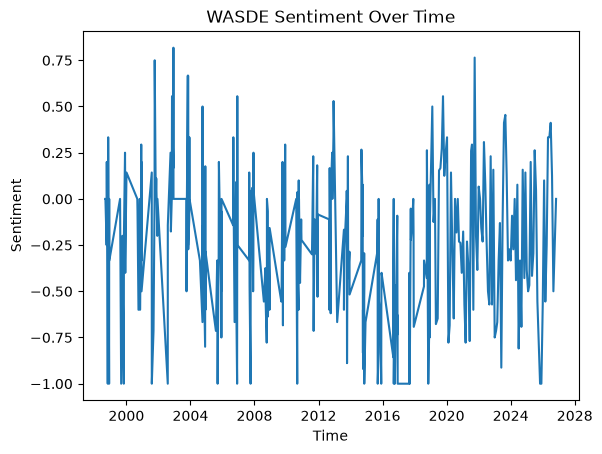

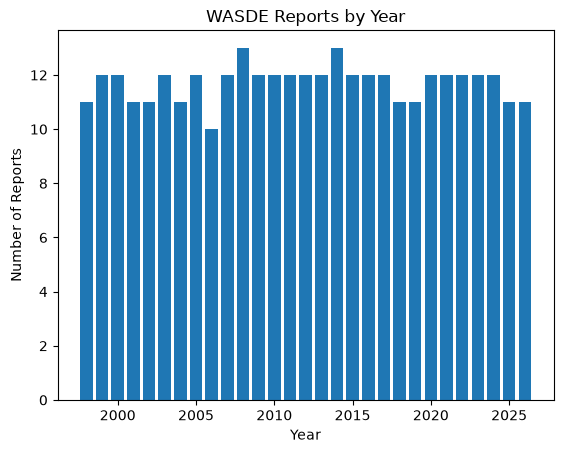

In [41]:
# Load and display data\wasde_sentiment_features.parquet
df = pd.read_parquet('data\wasde_sentiment_features.parquet')
df.head()

# Use matplotlib to plot lm_net_sentiment over time
import matplotlib.pyplot as plt

plt.plot(df['lm_net_sentiment'])
plt.xlabel('Time')
plt.ylabel('Sentiment')
plt.title('WASDE Sentiment Over Time')
plt.show()

# Display the number of reports by year
report_counts = df.groupby(df.index.year).size()
plt.bar(report_counts.index, report_counts.values)
plt.xlabel('Year')
plt.ylabel('Number of Reports')
plt.title('WASDE Reports by Year')
plt.show()

The two sentiment approaches use the same reports and the same forward-return target. We compare signal volatility, directional accuracy, correlation with future wheat returns, and the growth of a $1 signal-following strategy.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Inférence FinBERT sur 7549 phrases pertinentes (sur 340 rapports)...


100%|██████████| 472/472 [06:33<00:00,  1.20it/s]


Sentiment-method comparison:
                     Mean signal  Signal volatility  \
Rule-based NLP           -0.2422             0.3966   
FinBERT transformer      -0.0190             0.2485   

                     Correlation with next wheat return  Directional accuracy  
Rule-based NLP                                  -0.0332                0.3917  
FinBERT transformer                             -0.0110                0.4807  
Signal direction agreement: 69.1%


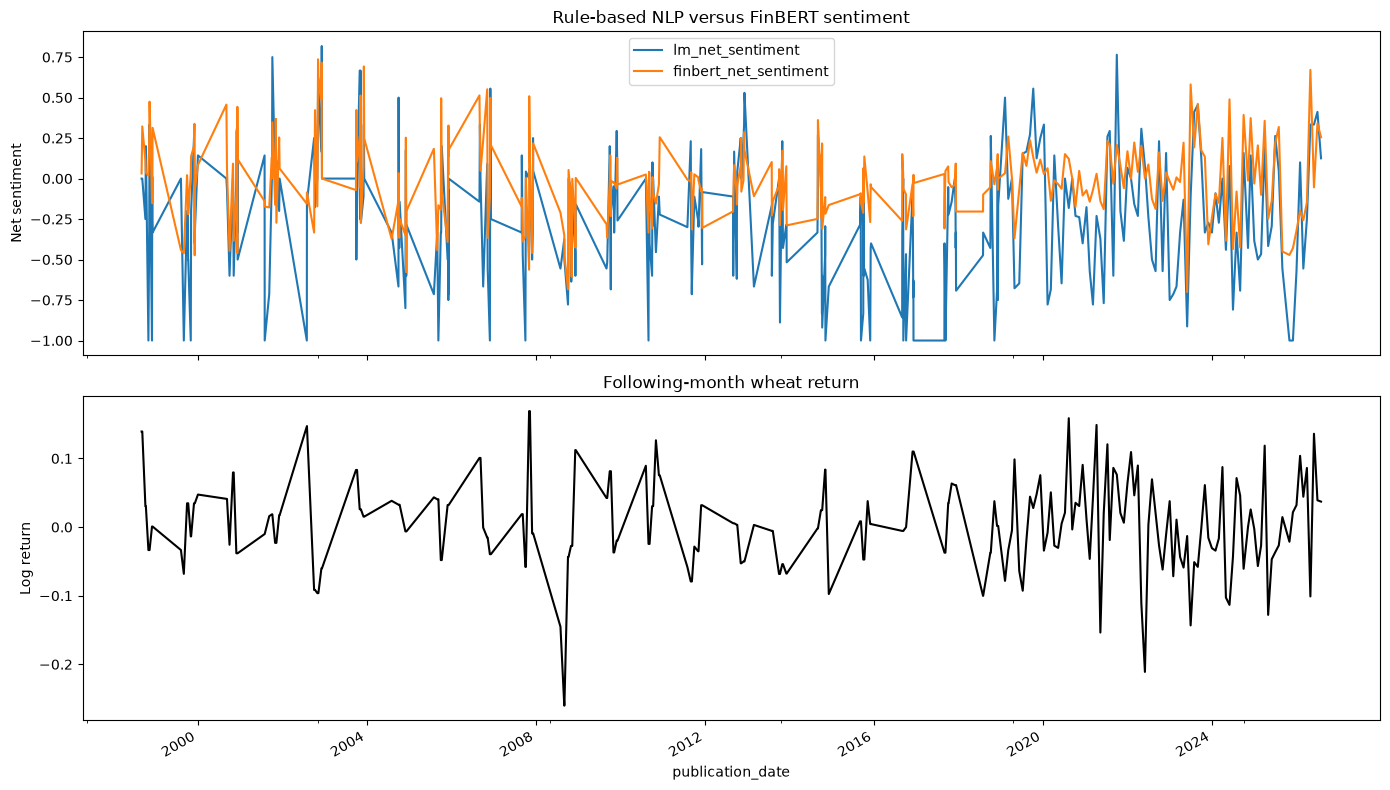

In [42]:
# Compare rule-based NLP with transformer language-model sentiment
# FinBERT is a pretrained transformer classifier, not a generative chat LLM.
comparison = df[["filename", "wheat_narrative", "lm_net_sentiment"]].copy()
comparison.index = pd.to_datetime(comparison.index)
comparison = comparison.rename_axis("publication_date").sort_index()

finbert_scores = compute_finbert_sentiment_v2(
    comparison["wheat_narrative"].fillna("").tolist(),
    batch_size=16,
)
if len(finbert_scores) != len(comparison) or pd.Series(finbert_scores).isna().any():
    raise RuntimeError(
        "FinBERT comparison could not be completed. Install transformers and torch "
        "and ensure the ProsusAI/finbert model is available."
    )
comparison["finbert_net_sentiment"] = finbert_scores

# Align both signals with the following month's wheat return.
wheat_monthly = wheat[["date", "wheat_price_usd"]].copy().set_index("date").sort_index()
wheat_monthly["next_month_return"] = np.log(
    wheat_monthly["wheat_price_usd"].shift(-1) / wheat_monthly["wheat_price_usd"]
)
comparison["month"] = comparison.index.to_period("M").to_timestamp()
comparison = comparison.reset_index().merge(
    wheat_monthly[["next_month_return"]].rename_axis("month").reset_index(),
    on="month",
    how="left",
).set_index("publication_date")
comparison = comparison.dropna(subset=["next_month_return"])

comparison["direction_agreement"] = (
    np.sign(comparison["lm_net_sentiment"])
    == np.sign(comparison["finbert_net_sentiment"])
)
metrics = pd.DataFrame({
    "Rule-based NLP": {
        "Mean signal": comparison["lm_net_sentiment"].mean(),
        "Signal volatility": comparison["lm_net_sentiment"].std(ddof=1),
        "Correlation with next wheat return": comparison[["lm_net_sentiment", "next_month_return"]].corr().iloc[0, 1],
        "Directional accuracy": (np.sign(comparison["lm_net_sentiment"]) == np.sign(comparison["next_month_return"])).mean(),
    },
    "FinBERT transformer": {
        "Mean signal": comparison["finbert_net_sentiment"].mean(),
        "Signal volatility": comparison["finbert_net_sentiment"].std(ddof=1),
        "Correlation with next wheat return": comparison[["finbert_net_sentiment", "next_month_return"]].corr().iloc[0, 1],
        "Directional accuracy": (np.sign(comparison["finbert_net_sentiment"]) == np.sign(comparison["next_month_return"])).mean(),
    }
}).T
print("Sentiment-method comparison:")
print(metrics.round(4))
print(f"Signal direction agreement: {comparison['direction_agreement'].mean():.1%}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
comparison[["lm_net_sentiment", "finbert_net_sentiment"]].plot(ax=axes[0])
axes[0].set_title("Rule-based NLP versus FinBERT sentiment")
axes[0].set_ylabel("Net sentiment")
comparison["next_month_return"].plot(ax=axes[1], color="black")
axes[1].set_title("Following-month wheat return")
axes[1].set_ylabel("Log return")
plt.tight_layout()
plt.show()

## 5. Walk-forward return and risk model

The portfolio is centered on wheat rather than a broad equity universe. RONI, WASDE sentiment, momentum, DXY, and WTI are used as predictors in a walk-forward return and risk model. The resulting position is volatility-targeted, capped, smoothed over time, and charged transaction costs to reduce look-ahead and turnover bias.


Strategy comparison including a $1 wheat buy-and-hold benchmark from 1992:
                                 Sharpe  Annual return  Annual volatility  \
Complete Ridge + rule-based NLP  0.4931         0.0555             0.1126   
Price + ONI                      0.4666         0.0548             0.1175   
Complete                         0.4234         0.0453             0.1069   
Momentum only                    0.2545         0.0244             0.0959   
Price + macro                    0.1747         0.0162             0.0928   
Complete + HGB                   0.0493         0.0059             0.1204   
Wheat buy-and-hold               0.0457         0.0108             0.2356   

                                 Average turnover  Observations  
Complete Ridge + rule-based NLP            0.2009         350.0  
Price + ONI                                0.2048         350.0  
Complete                                   0.1989         350.0  
Momentum only                              0

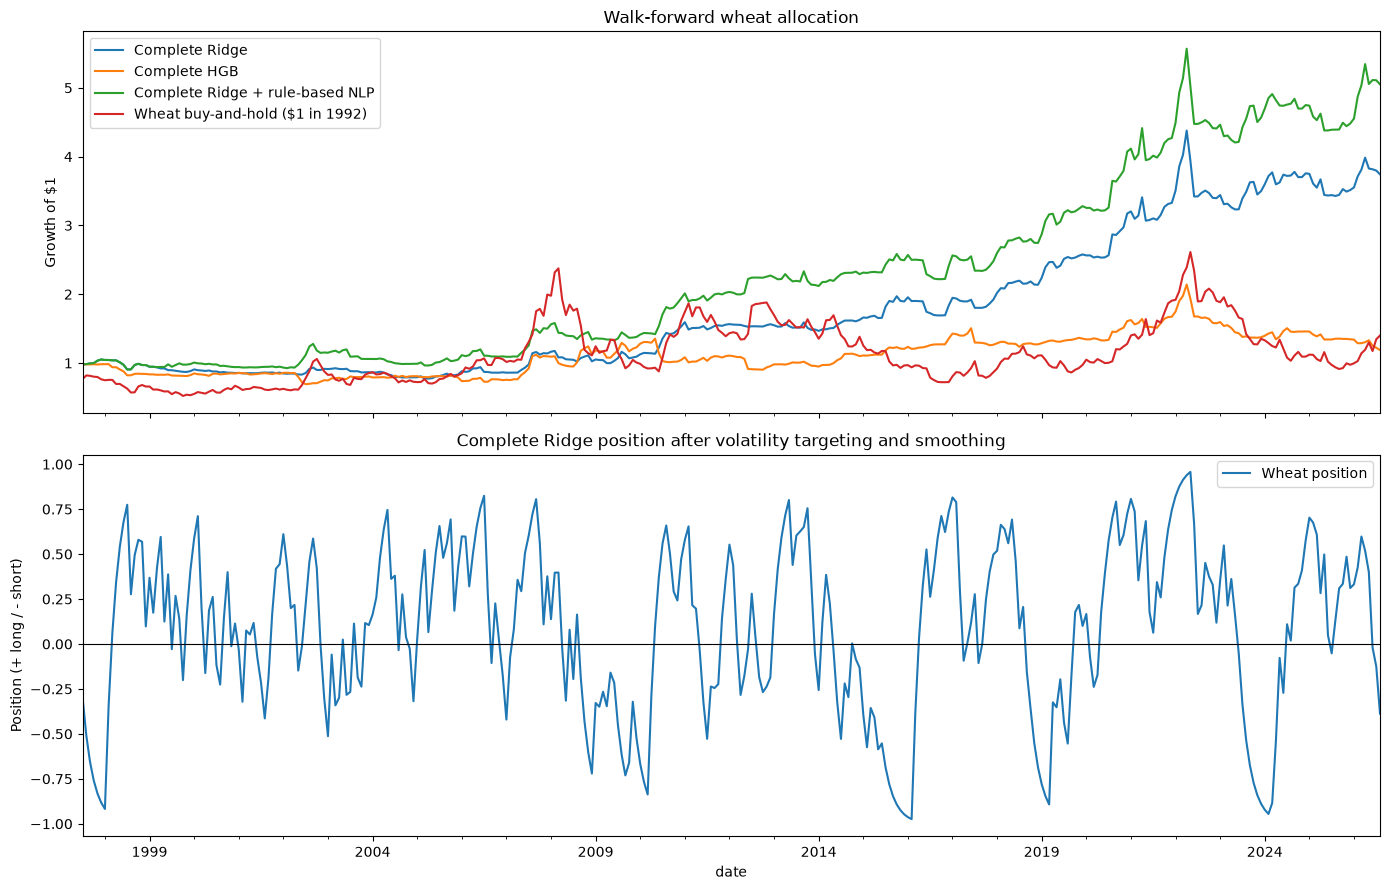

In [44]:
# Dynamic wheat allocation: predictive model, volatility targeting, and turnover control
# Every forecast is trained only on observations available before the holding month.

annualization = 12
lookback_months = 60
risk_free_annual = 0.0
risk_aversion = 4.0
target_vol_annual = 0.15
max_position = 1.0
smoothing = 0.30
transaction_cost = 0.0005

# 1. Build monthly prices and lagged alternative-information features.
model_data = market_inputs[["date", "wheat_price_usd", "wti_price_usd", "dxy_index"]].copy()
model_data["date"] = pd.to_datetime(model_data["date"])

roni_features = roni_monthly[["date", "roni_index"]].copy()
roni_features["date"] = pd.to_datetime(roni_features["date"]).dt.to_period("M").dt.to_timestamp()
roni_features = roni_features.groupby("date", as_index=False)["roni_index"].mean()

wasde_features = comparison[["finbert_net_sentiment"]].copy()
wasde_features.index = pd.to_datetime(wasde_features.index)
wasde_features = wasde_features.rename_axis("date").reset_index()
wasde_features["date"] = wasde_features["date"].dt.to_period("M").dt.to_timestamp()
wasde_features = wasde_features.groupby("date", as_index=False)["finbert_net_sentiment"].mean()

model_data = (
    model_data.merge(roni_features, on="date", how="left")
    .merge(wasde_features, on="date", how="left")
    .sort_values("date")
    .set_index("date")
)
model_data[["roni_index", "finbert_net_sentiment"]] = (
    model_data[["roni_index", "finbert_net_sentiment"]].shift(1).ffill().fillna(0.0)
)
model_data[["wheat_price_usd", "wti_price_usd", "dxy_index"]] = (
    model_data[["wheat_price_usd", "wti_price_usd", "dxy_index"]]
    .replace([np.inf, -np.inf], np.nan)
    .ffill()
)

wheat_returns = np.log(model_data["wheat_price_usd"]).diff()
model_data["wheat_return_1m"] = wheat_returns
model_data["wheat_return_3m"] = np.log(model_data["wheat_price_usd"]).diff(3)
model_data["wheat_vol_6m"] = wheat_returns.rolling(6).std()
model_data["dxy_return_1m"] = np.log(model_data["dxy_index"]).diff()
model_data["wti_return_1m"] = np.log(model_data["wti_price_usd"]).diff()
model_data["oni_change"] = model_data["roni_index"].diff()
model_data["el_nino_regime"] = (model_data["roni_index"] - 0.5).clip(lower=0.0)
model_data["la_nina_regime"] = (-0.5 - model_data["roni_index"]).clip(lower=0.0)

feature_columns = [
    "wheat_return_1m", "wheat_return_3m", "wheat_vol_6m",
    "roni_index", "oni_change", "el_nino_regime", "la_nina_regime",
    "finbert_net_sentiment", "dxy_return_1m", "wti_return_1m",
]
model_data["target_return"] = wheat_returns.shift(-1)
model_data["target_abs_return"] = model_data["target_return"].abs()
model_data = model_data.dropna(subset=feature_columns + ["target_return", "target_abs_return"])

# 2. Forecast return and conditional risk, then convert forecasts into a position.
def make_return_model(model_type):
    if model_type == "ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    if model_type == "hist_gradient_boosting":
        return HistGradientBoostingRegressor(
            max_iter=100, learning_rate=0.05, max_leaf_nodes=7,
            l2_regularization=1.0, random_state=42,
        )
    raise ValueError(f"Unknown return model: {model_type}")


def run_walk_forward(feature_subset, return_model_type="ridge", data_frame=None):
    data_frame = model_data if data_frame is None else data_frame
    rows = []
    previous_weight = 0.0
    monthly_target_vol = target_vol_annual / np.sqrt(annualization)

    for position in range(lookback_months, len(data_frame)):
        date = data_frame.index[position]
        training = data_frame.iloc[:position]
        train = training.dropna(subset=feature_subset + ["target_return", "target_abs_return"])
        if len(train) < lookback_months:
            continue

        return_model = make_return_model(return_model_type)
        risk_model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        return_model.fit(train[feature_subset], train["target_return"])
        risk_model.fit(train[feature_subset], train["target_abs_return"])

        current_x = data_frame.loc[[date], feature_subset]
        expected_return = float(return_model.predict(current_x)[0])
        predicted_sigma = max(float(risk_model.predict(current_x)[0]), 1e-4)
        raw_weight = expected_return / (risk_aversion * predicted_sigma**2)
        scaled_weight = raw_weight * monthly_target_vol / predicted_sigma
        target_weight = float(np.clip(scaled_weight, -max_position, max_position))
        weight = (1.0 - smoothing) * previous_weight + smoothing * target_weight

        asset_return = float(data_frame.loc[date, "target_return"])
        turnover = abs(weight - previous_weight)
        net_return = weight * asset_return - transaction_cost * turnover
        rows.append({
            "date": date, "weight": weight, "expected_return": expected_return,
            "predicted_sigma": predicted_sigma, "asset_return": asset_return,
            "turnover": turnover, "net_return": net_return,
        })
        previous_weight = weight

    return pd.DataFrame(rows).set_index("date")


# 3. Compare regularized linear and constrained tree models, plus ablation models.
feature_sets = {
    "Momentum only": ["wheat_return_1m", "wheat_return_3m", "wheat_vol_6m"],
    "Price + macro": [
        "wheat_return_1m", "wheat_return_3m", "wheat_vol_6m",
        "dxy_return_1m", "wti_return_1m",
    ],
    "Price + ONI": [
        "wheat_return_1m", "wheat_return_3m", "wheat_vol_6m",
        "roni_index", "oni_change", "el_nino_regime", "la_nina_regime",
    ],
    "Complete": feature_columns,
}

strategies = {
    name: run_walk_forward(columns, "ridge")
    for name, columns in feature_sets.items()
}
strategies["Complete + HGB"] = run_walk_forward(feature_columns, "hist_gradient_boosting")


# Re-run the complete Ridge strategy with the rule-based NLP signal.
rule_based_signal = (
    comparison.assign(month=comparison.index.to_period("M").to_timestamp())
    .groupby("month")["lm_net_sentiment"]
    .mean()
)
rule_based_model_data = model_data.copy()
rule_based_model_data["finbert_net_sentiment"] = (
    rule_based_signal.reindex(rule_based_model_data.index)
    .shift(1)
    .ffill()
    .fillna(0.0)
)
rule_based_result = run_walk_forward(
    feature_columns, "ridge", data_frame=rule_based_model_data
)
strategies["Complete Ridge + rule-based NLP"] = rule_based_result

# Buy-and-hold benchmark: invest $1 in wheat at the first available 1992 price.
buy_hold_prices = (
    market_inputs[["date", "wheat_price_usd"]]
    .dropna()
    .set_index("date")
    .sort_index()["wheat_price_usd"]
)
buy_hold_returns = np.log(buy_hold_prices).diff().dropna()
buy_hold_wealth = np.exp(buy_hold_returns.cumsum())
buy_hold_wealth = pd.concat([pd.Series({buy_hold_prices.index[0]: 1.0}), buy_hold_wealth])
buy_hold_wealth = buy_hold_wealth[~buy_hold_wealth.index.duplicated(keep="first")]


def annualized_sharpe(returns):
    volatility = returns.std(ddof=1)
    return np.nan if volatility == 0 else np.sqrt(annualization) * returns.mean() / volatility

summary = pd.DataFrame({
    name: {
        "Sharpe": annualized_sharpe(result["net_return"]),
        "Annual return": annualization * result["net_return"].mean(),
        "Annual volatility": np.sqrt(annualization) * result["net_return"].std(ddof=1),
        "Average turnover": result["turnover"].mean(),
        "Observations": len(result),
    }
    for name, result in strategies.items()
}).T.sort_values("Sharpe", ascending=False)
summary.loc["Wheat buy-and-hold"] = {
    "Sharpe": annualized_sharpe(buy_hold_returns),
    "Annual return": annualization * buy_hold_returns.mean(),
    "Annual volatility": np.sqrt(annualization) * buy_hold_returns.std(ddof=1),
    "Average turnover": 0.0,
    "Observations": len(buy_hold_returns),
}
summary = summary.sort_values("Sharpe", ascending=False)
print("Strategy comparison including a $1 wheat buy-and-hold benchmark from 1992:")
print(summary.round(4))

complete_result = strategies["Complete"]
complete_hgb_result = strategies["Complete + HGB"]
wealth = pd.DataFrame({
    "Complete Ridge": np.exp(complete_result["net_return"].cumsum()),
    "Complete HGB": np.exp(complete_hgb_result["net_return"].cumsum()),
    "Complete Ridge + rule-based NLP": np.exp(rule_based_result["net_return"].cumsum()),
    "Wheat buy-and-hold ($1 in 1992)": buy_hold_wealth,
})
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
wealth.plot(ax=axes[0])
axes[0].set_title("Walk-forward wheat allocation")
axes[0].set_ylabel("Growth of $1")
complete_result["weight"].plot(ax=axes[1], label="Wheat position")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_title("Complete Ridge position after volatility targeting and smoothing")
axes[1].set_ylabel("Position (+ long / - short)")
axes[1].legend()
plt.tight_layout()
plt.show()
